# The Path Less Travelled

This notebook will contain all the driving code for my honours project including synthetic data generation, real data preprocessing, model training, and evaluation. 

Text(0.5, 1.0, 'Reconstructed Ornstein-Uhlenbeck Process Paths from KL Decomposition')

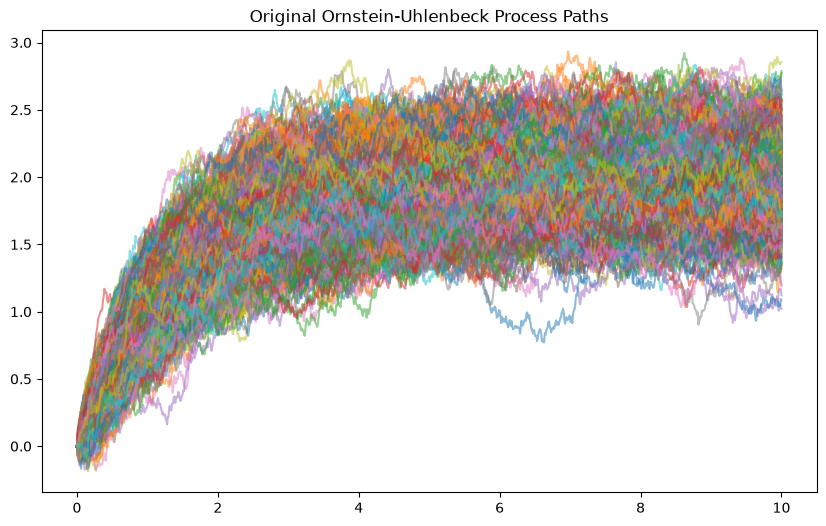

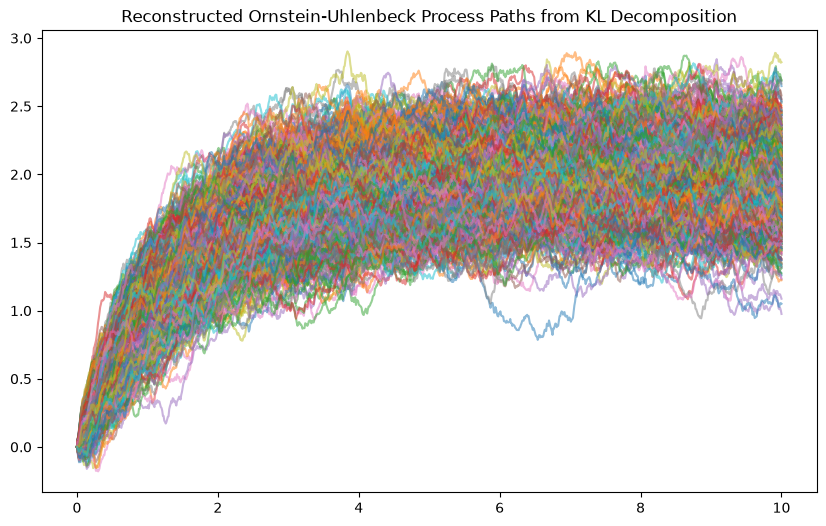

In [4]:
from wanderer import *
import numpy as np
import matplotlib.pyplot as plt



#KL decomposition of the OUP
#load the OUP process from json
OUP_process = StochasticProcess.from_json('OUP_process_EM.json')


coeffs, eigenfunctions, eigenvalues = KLDecomposition(OUP_process, 100)

OUP_reconstructed_process = reconstructFromKL(coeffs, eigenfunctions, OUP_process.timeGrid, OUP_process.timeHorizon)

#plot the original paths
plt.figure(figsize=(10, 6))
for i in range(OUP_process.num_paths):
    plt.plot(OUP_process.timeGrid, OUP_process.paths[i], alpha=0.5)
plt.title('Original Ornstein-Uhlenbeck Process Paths')

#plot the reconstructed paths
plt.figure(figsize=(10, 6))
for i in range(OUP_reconstructed_process.num_paths):
    plt.plot(OUP_reconstructed_process.timeGrid, OUP_reconstructed_process.paths[i], alpha=0.5)
plt.title('Reconstructed Ornstein-Uhlenbeck Process Paths from KL Decomposition')

Text(0.5, 1.0, 'Average Square Reconstruction Error Over Time (KL Decomposition)')

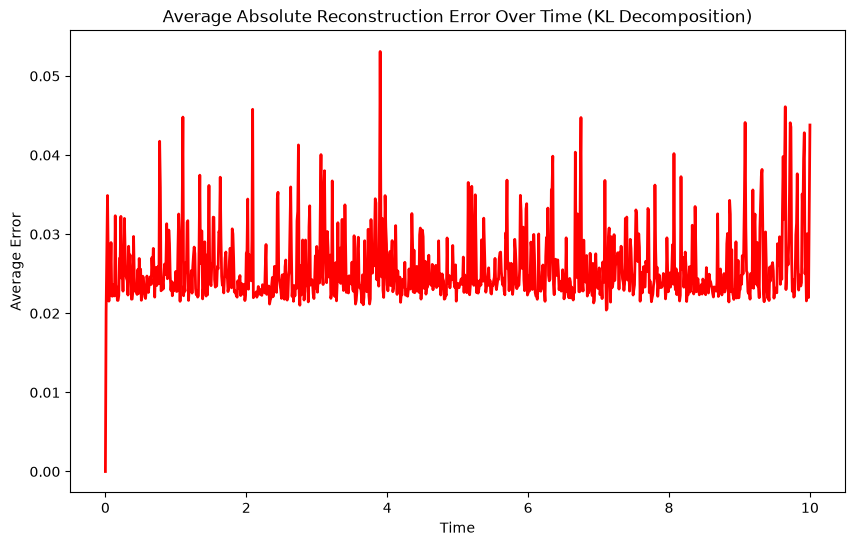

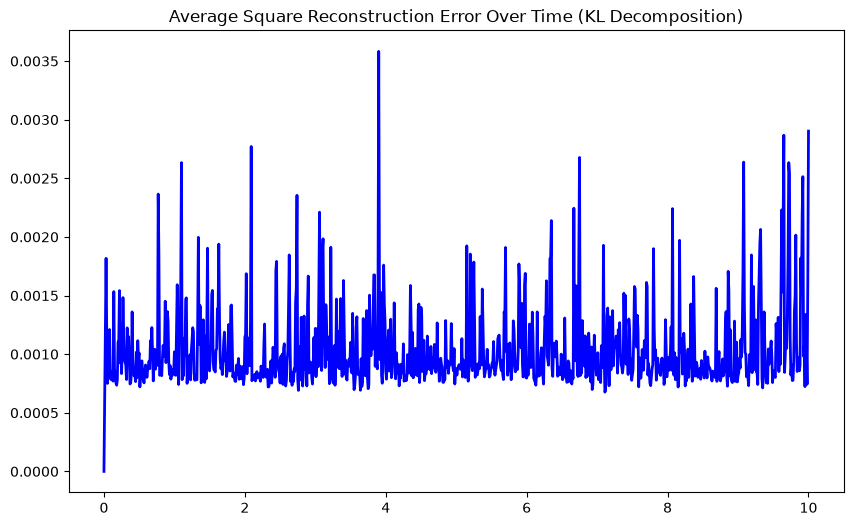

In [5]:
#plot l1 and l2 reconstruction error over time
errors = np.abs(OUP_reconstructed_process.paths - OUP_process.paths)
avg_errors = np.mean(errors, axis=0)
#plot the average reconstruction error over time
plt.figure(figsize=(10, 6))
plt.plot(OUP_process.timeGrid, avg_errors, color='red', linewidth=2)
plt.title('Average Absolute Reconstruction Error Over Time (KL Decomposition)')
plt.xlabel('Time')
plt.ylabel('Average Error')

errors_l2 = (np.mean((OUP_reconstructed_process.paths - OUP_process.paths)**2, axis=0))
#plot the average l2 reconstruction error over time
plt.figure(figsize=(10, 6))
plt.plot(OUP_process.timeGrid, errors_l2, color='blue', linewidth=2)
plt.title('Average Square Reconstruction Error Over Time (KL Decomposition)')

In [7]:
#slice the OUP process to one year intervals and stack them into a new process
sliced_processes = []
for i in range(0, OUP_process.timeHorizon, 1):
    sliced_processes.append(OUP_process.time_slice(i, i+1))

#stack the paths of the sliced processes into a new array
for i in range(len(sliced_processes)):
    if i == 0:
        stacked_paths = sliced_processes[i].paths
    else:
        stacked_paths = np.vstack((stacked_paths, sliced_processes[i].paths))

#find new time horizon
new_time_horizon = 1

# create a new process with the stacked paths
new_process = StochasticProcess(paths=stacked_paths, timeHorizon=new_time_horizon, timeStep=OUP_process.timeStep, method='stacked', num_paths=stacked_paths.shape[0])

#print dim of original process and new process
print(f'Original Process Shape: {OUP_process.paths.shape}')
print(f'New Process Shape: {new_process.paths.shape}')

#derive the KL coefficients of the new process
coeffs, eigenfunctions, eigenvalues = KLDecomposition(new_process, 100)

Original Process Shape: (1000, 1001)
New Process Shape: (10000, 100)


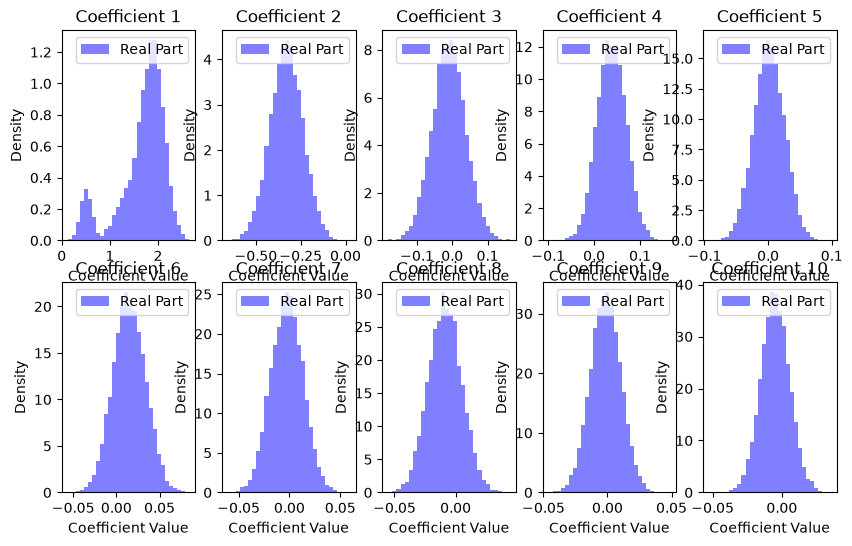

In [8]:
#plot the real and imaginary empirical distributions of the first 10 KL coefficients of the new process

plt.figure(figsize=(10, 6))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.hist(coeffs[:, i].real, bins=30, density=True, alpha=0.5, color='blue', label='Real Part')
    #plt.hist(coeffs[:, i].imag, bins=30, density=True, alpha=0.5, color='orange', label='Imaginary Part')
    plt.title(f'Coefficient {i+1}')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Density')
    plt.legend()

ValueError: could not broadcast input array from shape (100,) into shape (101,)

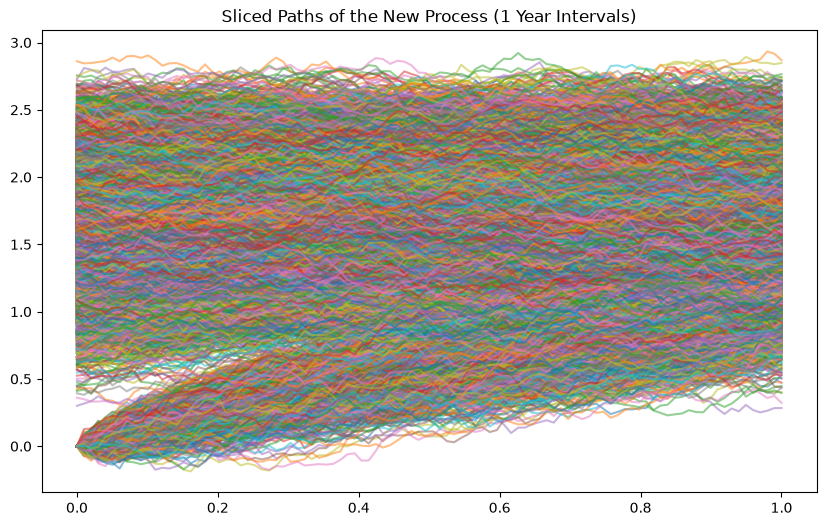

In [5]:
#plot sliced paths of the new process
plt.figure(figsize=(10, 6))
for i in range(new_process.num_paths):
    plt.plot(new_process.timeGrid, new_process.paths[i], alpha=0.5)
plt.title('Sliced Paths of the New Process (1 Year Intervals)')

# out of time simulation for a time period of 1 year
out_of_time_simulation = outOfTimeSimulationKL(distributions=coeffs, eigenfunctions = eigenfunctions, time_horizon= new_process.timeHorizon, time_step=new_process.timeStep, num_paths=1000)

#plot out of time simulation paths
plt.figure(figsize=(10, 6))
for i in range(out_of_time_simulation.num_paths):
    plt.plot(out_of_time_simulation.timeGrid, out_of_time_simulation.paths[i], alpha=0.5)
plt.title('Out of Time Simulation Paths (1 Year)')

Text(0.5, 1.0, 'Out of Time Simulation Paths (KL)')

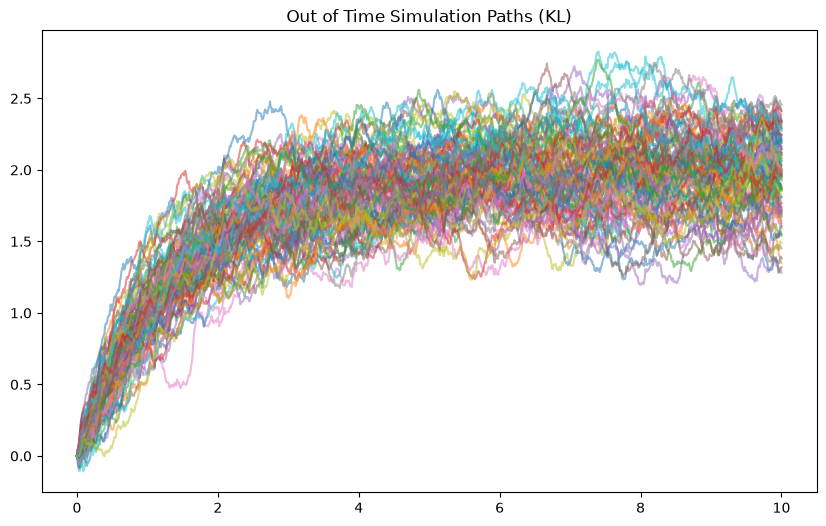

In [2]:

#run KL on unslice paths
coeffs_unsliced, eigenfunctions_unsliced = KLDecomposition(OUP_process, 100)

#simulate out of time paths using the unsliced KL coefficients and eigenfunctions
out_of_time_simulation_unsliced = outOfTimeSimulationKL(distributions=coeffs_unsliced, eigenfunctions = eigenfunctions_unsliced, time_horizon= OUP_process.timeHorizon, time_step=OUP_process.timeStep, num_paths=100)

#plot out of time simulation paths
plt.figure(figsize=(10, 6))
for i in range(out_of_time_simulation_unsliced.num_paths):
    plt.plot(out_of_time_simulation_unsliced.timeGrid, out_of_time_simulation_unsliced.paths[i], alpha=0.5)
plt.title('Out of Time Simulation Paths (KL)')